# Mechanics 6: Hamiltonian mechanics and phase space

*Learning path: mechanics, part 6 of 7.* [Index](README.md) · Previous: [Lagrangian mechanics](05-lagrangian-mechanics.ipynb) · Next: [Rigid bodies and non-inertial frames](07-rigid-bodies-and-frames.ipynb)

Why is energy conserved? Why momentum, why angular momentum? In 1918 Emmy Noether gave one answer to all three:
each conservation law comes from a **symmetry**. The laws of physics are the same today as tomorrow, so energy is
conserved; the same here as over there, so momentum is; the same in every direction, so angular momentum is. This
lesson rewrites mechanics in Hamilton's form, where a state is a point in **phase space** and motion is a flow of that
space, then proves Liouville's theorem (the flow never compresses) and uses Noether's theorem to solve the heavy
spinning top, wobbles and all.

**Who this is for.** You have done [lesson 5](05-lagrangian-mechanics.ipynb).

**What you will be able to do afterwards:**

1. pass from a Lagrangian to a Hamiltonian and write Hamilton's equations;
2. draw and read a phase portrait;
3. see Liouville's theorem at work, and how friction breaks it;
4. find conserved quantities from symmetries, and use them to solve the heavy top.

Plan about two hours.

## 1. From Lagrange to Hamilton

Lagrange uses a coordinate $q$ and its velocity $\dot q$. Hamilton trades the velocity for the **momentum**
$p = \partial L/\partial\dot q$, and the Lagrangian for the **Hamiltonian** $H = p\dot q - L$, written in terms of $q$
and $p$. For the pendulum (rate `w`, momentum `P`):

In [1]:
L = m*l^2*w^2/2 + m*g*l*cos(th);
P1 = diff(L, w)
wP = solve(P1 == P, w)
H = simplify(subs(P*w - L, w, wP))

l^2*m*w

> `diff` (see `deriv`): Derivative of expr with respect to the variable given (other letters count as constants: a partial derivative).

P/(l^2*m)

> Linear: w = −b/a = `P/(l^2*m)`.

(P^2-2*g*l^3*m^2*cos(th))/(2*l^2*m)

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

$H = P^2/(2ml^2) - mgl\cos\theta$: the kinetic plus the potential energy, now in terms of the momentum. The equations
of motion become a symmetric pair, **Hamilton's equations**:

$$\dot q = \frac{\partial H}{\partial p}, \qquad \dot p = -\frac{\partial H}{\partial q}.$$

In [2]:
simplify([diff(H, P), -diff(H, th)])

[P/(l^2*m), -g*l*m*sin(th)]

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

The first is $P = ml^2\dot\theta$ again; the second is the pendulum's Newton's law. Two first-order equations instead
of one second-order one, and the time derivative of $H$ along any motion is
$\partial_q H\,\dot q + \partial_p H\,\dot p = 0$: energy is conserved, whenever $H$ does not depend on time.

**Try this.** Find $H$ for a mass on a spring, $L = \tfrac12m\dot x^2 - \tfrac12kx^2$.

## 2. Phase space

The state of the pendulum is the pair $(\theta, p)$, a point in the plane called **phase space**. Since $H$ is
conserved, each motion runs along a level curve of $H$. With $m = l = g = 1$, $H = p^2/2 - \cos\theta$:

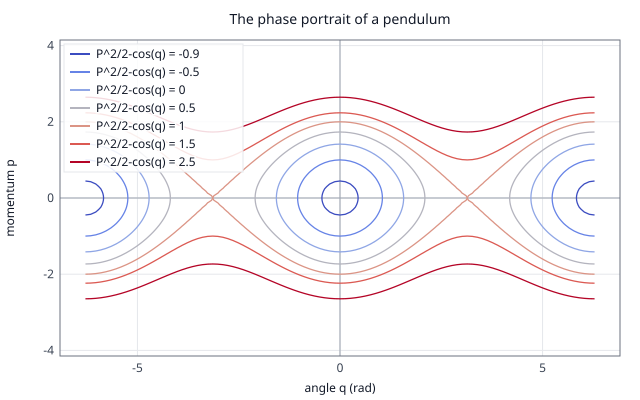

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [3]:
p = contour(P^2/2 - cos(q), q, -2*pi, 2*pi, P, -3, 3, [-0.9 -0.5 0 0.5 1 1.5 2.5]);
labels(title(p, "The phase portrait of a pendulum"), "angle q (rad)", "momentum p")

Three kinds of motion show up at a glance. Closed loops around $(0, 0)$ with $H < 1$: the pendulum swings back and
forth. Wavy lines at the top and bottom with $H > 1$: it goes over the top and keeps turning, one way or the other. And
between them, at $H = 1$ exactly, the **separatrix**: the curve through the upside-down position $q = \pm\pi$,
which the pendulum approaches forever without arriving.

**Try this.** What starting speed at the bottom puts the pendulum exactly on the separatrix?

## 3. Liouville's theorem

Don't follow one pendulum; follow a whole cloud of them, starting in a small disk of phase space around
$(q, p) = (1, 0)$ with radius 0.4. Each point moves by Hamilton's equations. After 4 time units:

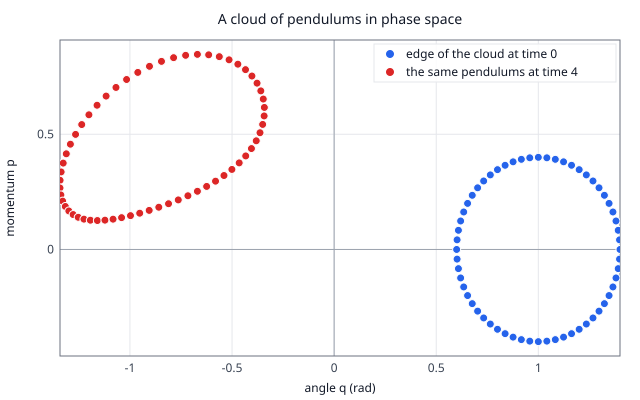

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [4]:
n = 60;
X0 = []; Y0 = []; X = []; Y = [];
for k in 1:n
  s = [1 + 0.4*cos(2*pi*k/n), 0.4*sin(2*pi*k/n)];
  D = odedata([P, -sin(q)], [q P], t, s, 0, 4, 40);
  X0 = append(X0, s(1)); Y0 = append(Y0, s(2));
  X = append(X, D(41, 2)); Y = append(Y, D(41, 3));
end
p = scatter(X0, Y0);
p = show(p, scatter(X, Y));
p = legend(p, "edge of the cloud at time 0", "the same pendulums at time 4");
labels(title(p, "A cloud of pendulums in phase space"), "angle q (rad)", "momentum p")

The disk has been sheared into a curved sliver, because pendulums with bigger swings take longer. But its area has not
changed. Measure both with the shoelace formula for a polygon:

In [5]:
function area(x, y)
  A = 0;
  m = numel(x);
  for k in 1:m
    j = mod(k, m) + 1;
    A = A + x(k)*y(j) - x(j)*y(k);
  end
  return A/2
end
eval([area(X0, Y0), area(X, Y)], 4)

[0.5017, 0.5017]

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

That is **Liouville's theorem**: the Hamiltonian flow preserves area in phase space (volume, with more coordinates).
The reason is one line: the velocity field $(\partial_pH, -\partial_qH)$ has divergence
$\partial_q\partial_pH - \partial_p\partial_qH = 0$. Friction breaks it. Add a drag $-0.3p$:

In [6]:
Xd = []; Yd = [];
for k in 1:n
  D = odedata([P, -sin(q) - 0.3*P], [q P], t, [X0(k), Y0(k)], 0, 4, 40);
  Xd = append(Xd, D(41, 2)); Yd = append(Yd, D(41, 3));
end
eval([area(Xd, Yd), area(X0, Y0)*exp(-0.3*4)], 4)

[0.1511, 0.1511]

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

The cloud shrinks by exactly $e^{-0.3t}$, the exponential of the divergence $-0.3$ times the time: it is sinking
towards the resting point. Liouville's theorem is the foundation of statistical mechanics: in a Hamiltonian system no
region of phase space is favoured by the flow.

## 4. Noether's theorem

If $L$ does not contain a coordinate $q$ (we say $q$ is **cyclic**), the Euler–Lagrange equation for it reads
$\frac{d}{dt}\partial L/\partial\dot q = 0$: the momentum $p = \partial L/\partial\dot q$ is conserved. Leaving $L$
unchanged when $q$ shifts is a symmetry, and **Noether's theorem** says every continuous symmetry gives a conserved
quantity this way:

| symmetry | conserved |
|---|---|
| shift in time | energy |
| shift in space | momentum |
| rotation | angular momentum |

**The heavy top.** A symmetric top pivoting on its tip is described by three angles: the tilt $\theta$ of its axis,
the direction $\phi$ the axis points (the precession), and the spin angle $\psi$ about the axis. With $I_1$ the moment
of inertia about a horizontal axis through the tip, $I_3$ about the symmetry axis, and $M = mgd$:

In [7]:
L = I1/2*(wt^2 + wf^2*sin(th)^2) + I3/2*(wp + wf*cos(th))^2 - M*cos(th);
pf = diff(L, wf)
pp = diff(L, wp)

I1*wf*sin(th)^2+I3*cos(th)*(wf*cos(th)+wp)

> `diff` (see `deriv`): Derivative of expr with respect to the variable given (other letters count as constants: a partial derivative).

I3*(wf*cos(th)+wp)

> `diff` (see `deriv`): Derivative of expr with respect to the variable given (other letters count as constants: a partial derivative).

$L$ contains neither $\phi$ (it looks the same from every compass direction) nor $\psi$ (the top is round), so both
momenta are conserved. The second is $I_3\omega_3$: the spin $\omega_3 = \dot\psi + \dot\phi\cos\theta$ never
changes. Solving the first for $\dot\phi$ gives the precession rate in terms of $\theta$, and only the $\theta$
equation is left:

In [8]:
dL = diff(L, th)

I1*wf^2*sin(th)*cos(th)-I3*wf*sin(th)*(wf*cos(th)+wp)+M*sin(th)

> `diff` (see `deriv`): Derivative of expr with respect to the variable given (other letters count as constants: a partial derivative).

Take the toy top of [lesson 3](03-rotation.ipynb) ($m = 0.1$ kg, $d = 4$ cm, $I_3 = 4\cdot10^{-5}$ kg·m², spin 200 per
second), with $I_1 = 2\cdot10^{-4}$ kg·m². Release it at 30° with its axis at rest, so $\dot\phi = 0$ at the start and
$p_\phi = I_3\omega_3\cos 30°$:

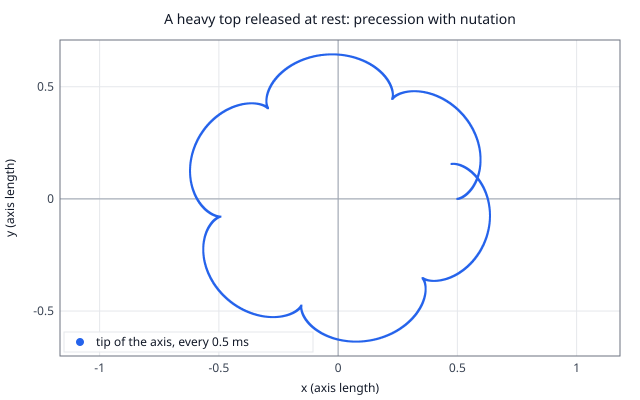

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [9]:
I1 = 2e-4; I3 = 4e-5; M = 0.1*9.81*0.04; w3 = 200; t0 = pi/6;
b = I3*w3*cos(t0);
fdot = (b - I3*w3*cos(th))/(I1*sin(th)^2);
acc = (I1*fdot^2*sin(th)*cos(th) - I3*w3*fdot*sin(th) + M*sin(th))/I1;
D = odedata([wt, acc, fdot], [th wt ph], t, [t0, 0, 0], 0, 1.2, 2400);
p = scatter(D, [t th wt ph], [sin(th)*cos(ph), sin(th)*sin(ph)]);
p = legend(p, "tip of the axis, every 0.5 ms");
labels(title(p, "A heavy top released at rest: precession with nutation"), "x (axis length)", "y (axis length)")

Seen from above, the tip of the axis goes around (precession, as in lesson 3) while bobbing up and down between two
circles (**nutation**), drawing cusps where it stops for an instant. The tilt stays between

In [10]:
eval([min(column(D, 2)), max(column(D, 2))]*180/pi, 3)

[30.0, 40.2]

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

degrees. Released with a sideways push at the precession rate $\Omega$ of lesson 3, the nutation becomes much smaller
(exercise 5). A real top's nutation dies out through friction, leaving the smooth precession you see.

**Try this.** Double the spin to 400 per second. What happens to the nutation?

## Summary

* Hamilton's form: $p = \partial L/\partial\dot q$, $H = p\dot q - L$, $\dot q = \partial_pH$, $\dot p = -\partial_qH$.
* Each motion runs along a level curve of $H$ in phase space; the separatrix divides swinging from turning.
* Liouville: Hamiltonian flow preserves phase-space volume; friction makes it shrink.
* Noether: a symmetry of $L$ gives a conserved quantity. The heavy top has three (energy, $p_\phi$, $p_\psi$) and is
  solved by them.

Next: [rigid bodies and non-inertial frames](07-rigid-bodies-and-frames.ipynb).

## Exercises

1. **Free particle.** For $L = \tfrac12m(\dot x^2 + \dot y^2)$, find the momenta and $H$. Which symmetries does $L$
   have?
2. **Central force.** For $L = \tfrac12m(\dot r^2 + r^2\dot\theta^2) - V(r)$, find $H$ and the conserved $p_\theta$.
3. **Oscillator flow.** Show that for $H = \tfrac12(p^2 + q^2)$ the flow rotates phase space rigidly. What happens to
   the cloud of section 3?
4. **Damped area.** Show that for $\dot q = p$, $\dot p = -\sin q - \gamma p$ the divergence is $-\gamma$, so areas
   shrink like $e^{-\gamma t}$.
5. **Smooth precession.** Start the top with $\dot\phi = 4.905$ per second instead of 0, so
   $p_\phi = I_1\dot\phi\sin^2\theta_0 + I_3\omega_3\cos\theta_0$. How large is the nutation now?
6. **Sleeping top.** A top spinning exactly upright ($\theta = 0$) is stable if $I_3^2\omega_3^2 > 4I_1M$. Is the toy
   top at 200 per second stable upright? Below what spin does it start to wobble?

## Hints and answers

* **Section 1, Try this.** $H = p^2/(2m) + \tfrac12kx^2$.
* **Section 2, Try this.** $H = 1$ with $q = 0$ needs $p^2/2 = 2$, so $p = 2$: speed $2\sqrt{gl}$.
* **Section 4, Try this.** The tilt now stays between 30° and 32°, against 30° to 40°: for a fast top the nutation
  shrinks like $1/\omega_3^2$, and its cusps come twice as often.
* **Exercise 1.** $p_x = m\dot x$, $p_y = m\dot y$, $H = (p_x^2 + p_y^2)/2m$; shifts in $x$ and $y$, rotations, and
  time shifts.
* **Exercise 2.** $p_\theta = mr^2\dot\theta$ and $H = p_r^2/2m + p_\theta^2/(2mr^2) + V(r)$.
* **Exercise 3.** All points go around circles at the same rate, so the disk turns without changing shape.
* **Exercise 4.** $\partial_q(p) + \partial_p(-\sin q - \gamma p) = -\gamma$.
* **Exercise 5.** Replace `b` by `I1*4.905*sin(t0)^2 + I3*w3*cos(t0)` and start with the same `[t0, 0, 0]`: the tilt
  stays between 30° and 31.3°, against 30° to 40.2° before. (The rate 4.905 is the fast-top estimate of lesson 3; the
  exact steady rate makes the right side of the $\theta$ equation zero at 30°.)
* **Exercise 6.** $I_3^2\omega_3^2 = 6.4\cdot10^{-5}$ against $4I_1M = 3.1\cdot10^{-5}$: stable. It starts to wobble
  below $\omega_3 = \sqrt{4I_1M}/I_3 \approx 140$ per second.

## Sources

1. W. R. Hamilton, "Second essay on a general method in dynamics", *Philosophical Transactions of the Royal Society*
   125, 95–144 (1835).
2. J. Liouville, "Note sur la théorie de la variation des constantes arbitraires", *Journal de Mathématiques Pures et
   Appliquées* 3, 342–349 (1838).
3. E. Noether, "Invariante Variationsprobleme", *Nachrichten von der Gesellschaft der Wissenschaften zu Göttingen*,
   235–257 (1918). English translation by M. A. Tavel, *Transport Theory and Statistical Physics* 1, 186–207 (1971).
4. H. Goldstein, C. Poole and J. Safko, *Classical Mechanics*, 3rd ed., Addison-Wesley (2002), sections 5.7, 8.1 and
   9.9.